# CNN for patches of 15x15 pixels

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch,evaluate

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils.class_weight import compute_class_weight

import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout

N_PIXELS = 100
PATCH_SIZE = 15

I0000 00:00:1795531899.587767   77419 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795531899.590992   77419 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795531899.790924   77419 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795531903.551304   77419 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [4]:
X_train, y_train, _ = build_patches_dataset(nyu, train_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE)
X_test, y_test, _ = build_patches_dataset(nyu, test_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE)
X_val, y_val, _ = build_patches_dataset(nyu, val_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE)

In [5]:
model = Sequential()
model.add(Conv2D(32, (3, 3), padding='same',
                 input_shape=X_train[0].shape))
model.add(Activation('relu'))
model.add(Conv2D(32, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), padding='same'))
model.add(Activation('relu'))
model.add(Conv2D(64, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))

/opt/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1795531987.661296   77419 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [6]:
model.compile(optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy', keras.metrics.AUC(name='auc')])

In [7]:
# Balance floor vs not-floor, like class_weight="balanced" in the logistic notebooks
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=256,
                    validation_data=(X_val, y_val),
                    class_weight=class_weight,
                    callbacks=[early_stop])

Epoch 1/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - accuracy: 0.6129 - auc: 0.6737 - loss: 0.6424 - val_accuracy: 0.7819 - val_auc: 0.7123 - val_loss: 0.5246
Epoch 2/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 22s 56ms/step - accuracy: 0.6088 - auc: 0.7050 - loss: 0.6226 - val_accuracy: 0.5611 - val_auc: 0.7290 - val_loss: 0.6576
Epoch 3/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - accuracy: 0.6128 - auc: 0.7144 - loss: 0.6150 - val_accuracy: 0.6214 - val_auc: 0.7384 - val_loss: 0.6355
Epoch 4/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - accuracy: 0.6210 - auc: 0.7231 - loss: 0.6082 - val_accuracy: 0.5128 - val_auc: 0.7346 - val_loss: 0.7252
Epoch 5/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 23s 56ms/step - accuracy: 0.6331 - auc: 0.7328 - loss: 0.6017 - val_accuracy: 0.6125 - val_auc: 0.7248 - val_loss: 0.6166
Epoch 6/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - accuracy: 0.6529 - auc: 0.7499 - loss: 0.5884 - val_accuracy: 0.6667 - val_auc: 0.7571 - val_loss: 0.5958
Epoch 7/30
402/402 ━━━━━━━━━

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step
AUC:      0.793
AP:       0.353
Accuracy: 0.619  (baseline 'always not floor': 0.885)
IoU:      0.199
              precision    recall  f1-score   support

   not floor       0.96      0.59      0.73     19035
       floor       0.21      0.82      0.33      2465

    accuracy                           0.62     21500
   macro avg       0.59      0.71      0.53     21500
weighted avg       0.88      0.62      0.69     21500



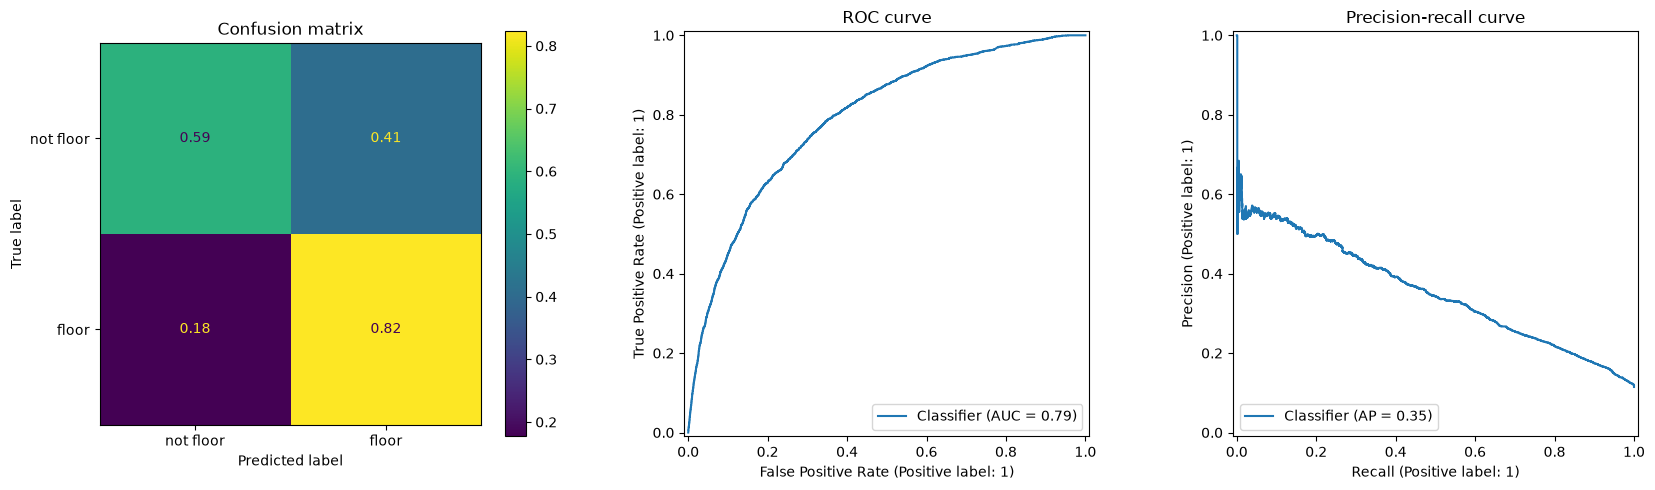

In [8]:
y_proba = model.predict(X_test, batch_size=1024).ravel()
evaluate(y_test, y_proba)

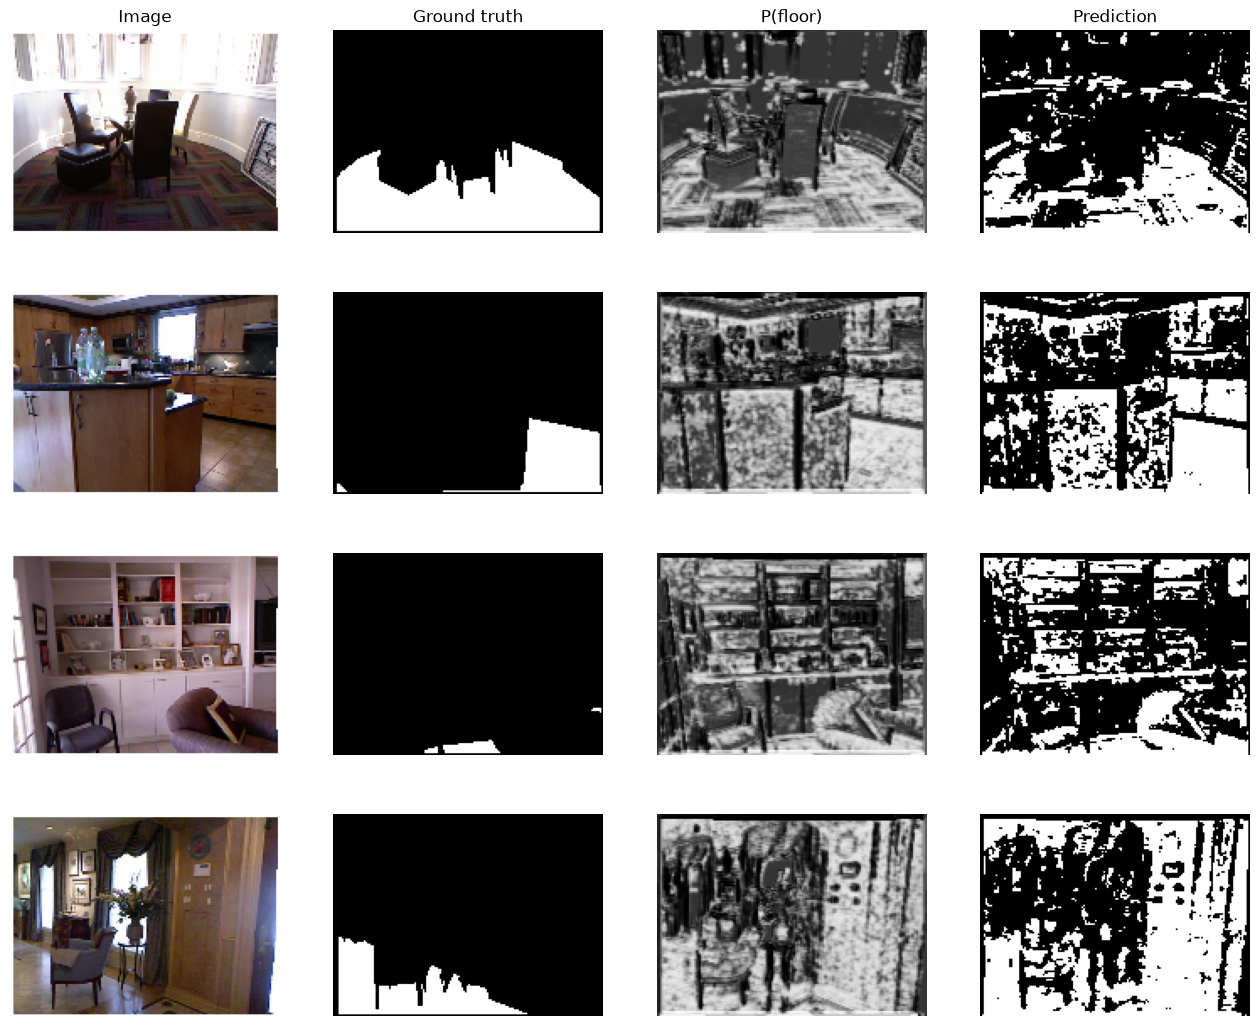

In [9]:
STRIDE = 4   # predict one pixel every 4 (faster)
p = PATCH_SIZE // 2

fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # Build one patch for each pixel on the grid
    padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode="edge")
    rows = range(0, image.shape[0], STRIDE)
    cols = range(0, image.shape[1], STRIDE)
    X = np.array([extract_patch(padded, r + p, c + p, PATCH_SIZE) for r in rows for c in cols])
    X = X.astype(np.float32) / 255.0

    # Predict and put back into a (small) image
    proba = model.predict(X, batch_size=2048, verbose=0).reshape(len(rows), len(cols))
    pred = proba > 0.5

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()